# King County Housing Market Analysis for Erin Robinson

This notebook presents an exploratory data analysis (EDA) of the King County housing market with a focus on supporting **Erin Robinson**, a socially responsible real estate investor. Erin's goal is to identify properties in lower-income or undervalued neighborhoods where strategic investments can generate a modest profit while contributing to neighborhood improvement.

The analysis combines data exploration, statistical insights, and geographic patterns to identify promising investment opportunities. Based on the findings, the notebook concludes with practical recommendations tailored to Erin's investment strategy, balancing financial sustainability with positive community impact.

## 1) Setup 

In [180]:
#looking at the data
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns 
import matplotlib.pyplot as plt
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

## 2) Dataset Overview

The data has been exported from the PostgreSQL in notebook `1_Fetching_the_data.ipynb`. The King County Housing Dataset contains information on residential property sales in King County, Washington, USA. Each record represents a home sale and includes details about the property's sale price, location, physical characteristics, condition, and surrounding area.

In [181]:
df_housesales = pd.read_csv("data/eda_housesales.csv")
df_housesales.sample(3)

,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,date,price
14696,3876540410,3.0,2.25,1690.0,7292.0,1.0,0.0,0.0,3,7,...,440.0,1985,0.0,98003,47.2639,-122.303,1670.0,7747.0,2015-04-13,242000.0
14612,179001046,3.0,2.50,1190.0,3000.0,2.0,0.0,0.0,3,7,...,0.0,2002,NaN,98178,47.4933,-122.275,1190.0,3000.0,2014-05-08,229000.0
21244,1776230190,4.0,3.50,3170.0,3858.0,2.0,0.0,0.0,3,8,...,640.0,2008,0.0,98059,47.5049,-122.155,2640.0,3844.0,2015-04-08,495000.0


In [182]:
#print columns
df_housesales.columns

Index(['id', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'grade', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long',
       'sqft_living15', 'sqft_lot15', 'date', 'price'],
      dtype='object')

In [183]:
#overview 
df_housesales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21597 non-null  int64  
 1   bedrooms       21597 non-null  float64
 2   bathrooms      21597 non-null  float64
 3   sqft_living    21597 non-null  float64
 4   sqft_lot       21597 non-null  float64
 5   floors         21597 non-null  float64
 6   waterfront     19206 non-null  float64
 7   view           21534 non-null  float64
 8   condition      21597 non-null  int64  
 9   grade          21597 non-null  int64  
 10  sqft_above     21597 non-null  float64
 11  sqft_basement  21145 non-null  float64
 12  yr_built       21597 non-null  int64  
 13  yr_renovated   17749 non-null  float64
 14  zipcode        21597 non-null  int64  
 15  lat            21597 non-null  float64
 16  long           21597 non-null  float64
 17  sqft_living15  21597 non-null  float64
 18  sqft_l

The dataset contains variables such as:
- **Sale information**: sale price and sale date.
- **Property characteristics**: number of bedrooms and bathrooms, living area, lot size, number of floors, waterfront status, and view quality.
- **Property quality**: condition, construction grade, and renovation history.
- **Location**: ZIP code, latitude, and longitude.
- **Additional features**: basement size, year built, and year renovated.

## 3) Hypotheses

Recall that our client Erin wants to focus on low-income / undervalued neighborhoods, which will contain cheaper houses. Based on Erin's investment strategy, we formulated three hypotheses that will be explored throughout this analysis: 

| **Hypothesis** | **Description** |
|----------------|-----------------|
| **1** | Smaller houses will have a lower sale price. |
| **2a** | Low-graded houses have a lower price per square foot. |
| **2b** | Houses in poorer condition have a lower price per square foot. |
| **3** | Older, unrenovated houses have a lower price per square foot. |

## 4) Data Exploration and Cleaning

Since the analysis is targeted to Erin's needs, it will only focus on certain columns of the dataset, irrelevant variables can be deleted.

In [184]:
#create a subset with relevant variables 
housing_subset = df_housesales[["id","price","date", "yr_built","yr_renovated","zipcode","lat","long","grade","condition","sqft_living","sqft_lot"]].copy()
housing_subset.head()

,id,price,date,yr_built,yr_renovated,zipcode,lat,long,grade,condition,sqft_living,sqft_lot
0,7129300520,221900.0,2014-10-13,1955,0.0,98178,47.5112,-122.257,7,3,1180.0,5650.0
1,6414100192,538000.0,2014-12-09,1951,19910.0,98125,47.7210,-122.319,7,3,2570.0,7242.0
2,5631500400,180000.0,2015-02-25,1933,NaN,98028,47.7379,-122.233,6,3,770.0,10000.0
3,2487200875,604000.0,2014-12-09,1965,0.0,98136,47.5208,-122.393,7,5,1960.0,5000.0
4,1954400510,510000.0,2015-02-18,1987,0.0,98074,47.6168,-122.045,8,3,1680.0,8080.0


In [185]:
#check for duplicate values
housing_subset.duplicated().value_counts()

False    21597
Name: count, dtype: int64

There are no duplicate rows. Let's take a closer look at the id variable. 

In [186]:
total_rows = len(housing_subset)
unique_houses = housing_subset['id'].nunique()
duplicate_rows = housing_subset['id'].duplicated().sum()

print(f"Total rows: {total_rows}")
print(f"Unique houses: {unique_houses}")
print(f"Duplicate ID rows: {duplicate_rows}")

Total rows: 21597
Unique houses: 21420
Duplicate ID rows: 177


In [187]:
# Show all rows where the house ID appears more than once
duplicate_rows = housing_subset[
    housing_subset['id'].duplicated(keep=False)
].sort_values('id')

duplicate_rows.head(5)

,id,price,date,yr_built,yr_renovated,zipcode,lat,long,grade,condition,sqft_living,sqft_lot
2494,1000102,280000.0,2014-09-16,1991,0.0,98002,47.3262,-122.214,7,3,2400.0,9373.0
2495,1000102,300000.0,2015-04-22,1991,0.0,98002,47.3262,-122.214,7,3,2400.0,9373.0
16800,7200179,150000.0,2014-10-16,1925,NaN,98055,47.4840,-122.211,6,3,840.0,12750.0
16801,7200179,175000.0,2015-04-24,1925,NaN,98055,47.4840,-122.211,6,3,840.0,12750.0
11421,109200390,245000.0,2014-08-20,1980,0.0,98023,47.2977,-122.367,7,4,1480.0,3900.0


A small number of houses were sold more than once on different dates. Because the analysis and hypotheses focus on individual houses rather than sales transactions, only the most recent sale record for each house should be retained. This will be filtered below.

In [188]:
housing_subset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21597 entries, 0 to 21596
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            21597 non-null  int64  
 1   price         21597 non-null  float64
 2   date          21597 non-null  object 
 3   yr_built      21597 non-null  int64  
 4   yr_renovated  17749 non-null  float64
 5   zipcode       21597 non-null  int64  
 6   lat           21597 non-null  float64
 7   long          21597 non-null  float64
 8   grade         21597 non-null  int64  
 9   condition     21597 non-null  int64  
 10  sqft_living   21597 non-null  float64
 11  sqft_lot      21597 non-null  float64
dtypes: float64(6), int64(5), object(1)
memory usage: 2.0+ MB


The date variable has the dtype object, but it should be a datetime variable.

In [189]:
#convert date variable to datetime format
housing_subset["date"] = pd.to_datetime(housing_subset["date"], format="%Y-%m-%d")
housing_subset['date'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 21597 entries, 0 to 21596
Series name: date
Non-Null Count  Dtype         
--------------  -----         
21597 non-null  datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 168.9 KB


After converting the date variable, we can filter for the most recent sale for each house.

In [190]:
# Keep the most recent sale for each house

# Number of rows before removing duplicate house IDs
rows_before = len(housing_subset)

# Keep the most recent sale for each house
housing_subset = (
    housing_subset
    .sort_values('date')
    .drop_duplicates(subset='id', keep='last')
    .copy()
)

# Number of rows after
rows_after = len(housing_subset)
rows_dropped = rows_before - rows_after

print(f"Rows before: {rows_before:,}")
print(f"Rows after: {rows_after:,}")
print(f"Sale records dropped: {rows_dropped:,}")
print(f"Number of unique houses: {housing_subset['id'].nunique():,}")

Rows before: 21,597
Rows after: 21,420
Sale records dropped: 177
Number of unique houses: 21,420


Let's look for missing values.

<Axes: >

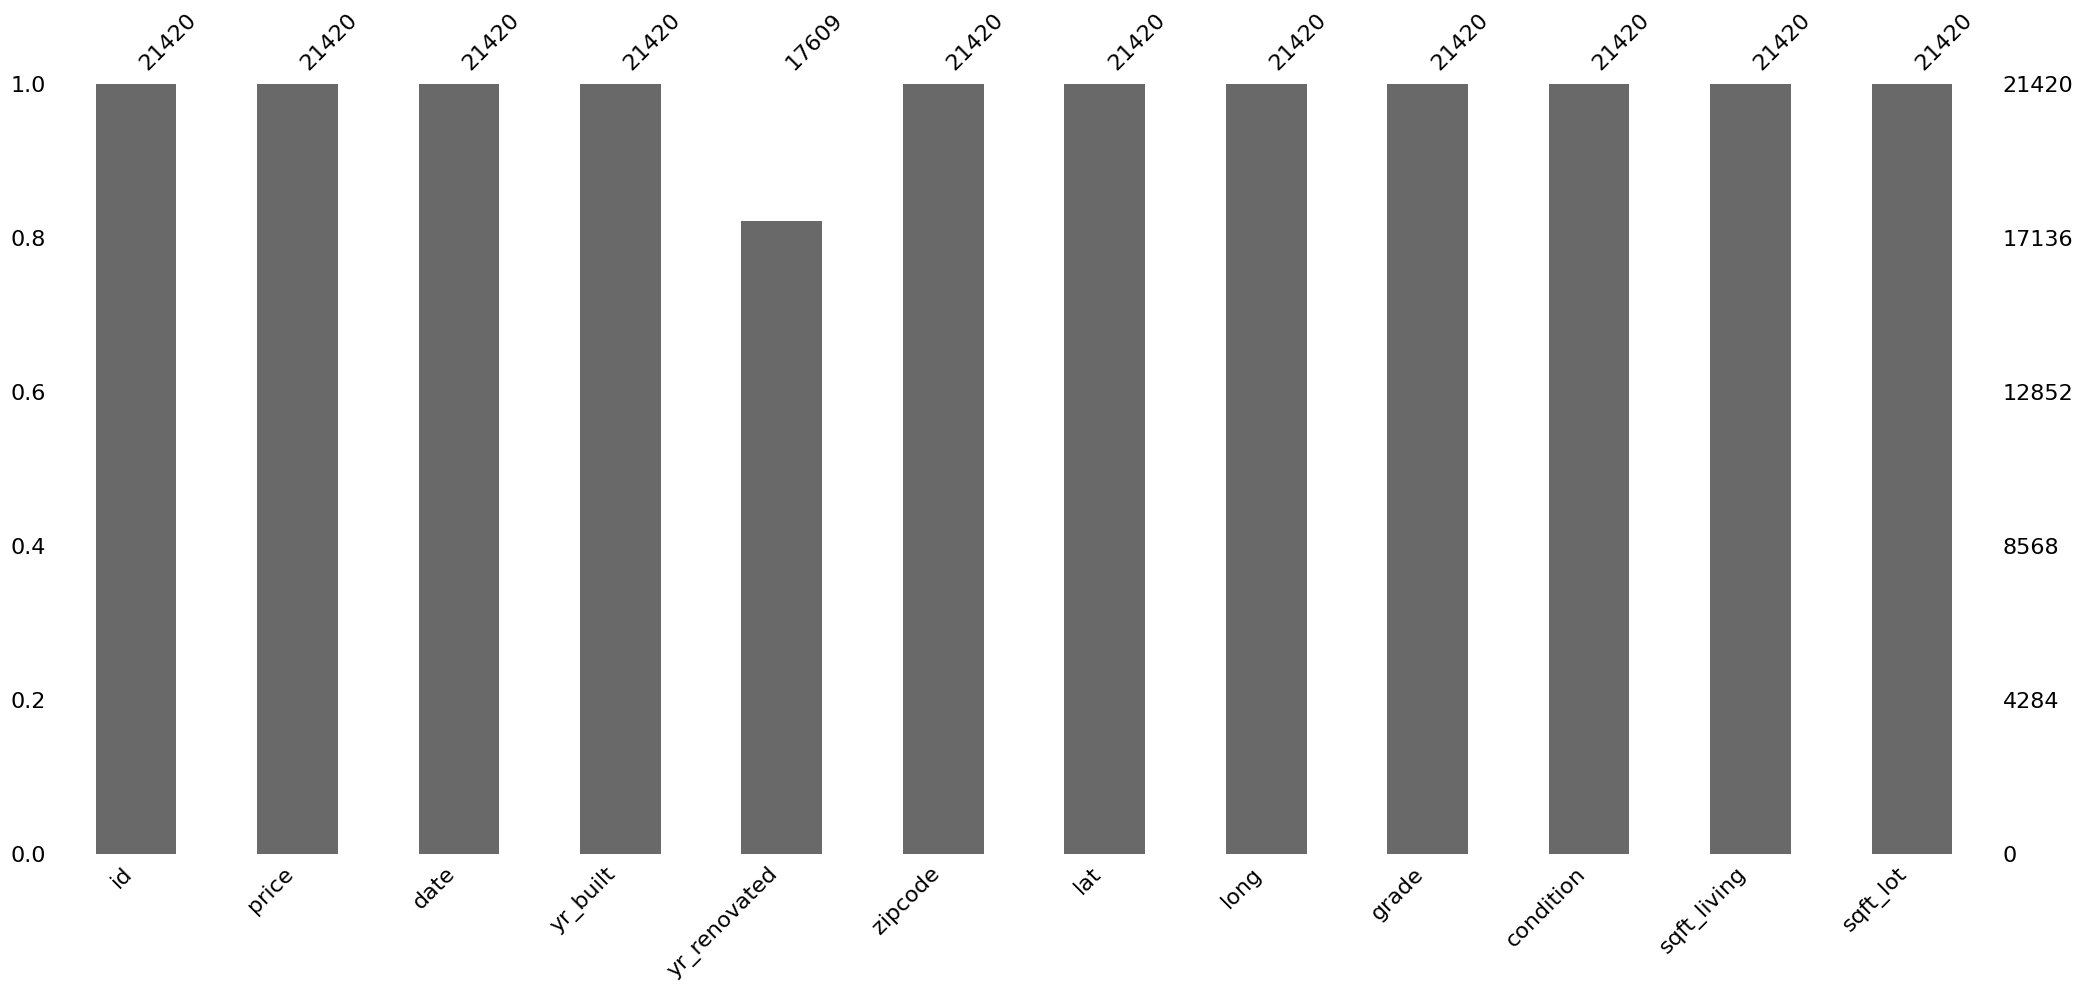

In [191]:
msno.bar(housing_subset)

In [192]:
#the yr_renovated column has missing values
missing = housing_subset['yr_renovated'].isnull().sum()

print(f"Missing values in the yr_renovated column: {missing}")

Missing values in the yr_renovated column: 3811


In [193]:
housing_subset['yr_renovated'].unique()

array([    0.,    nan, 19940., 20110., 19540., 19920., 20040., 20130.,
       19860., 20140., 20050., 20020., 19840., 19560., 20010., 19900.,
       20000., 20100., 20030., 19770., 19960., 20070., 19700., 19830.,
       19750., 19980., 19710., 19880., 20090., 19990., 19970., 19690.,
       19950., 20150., 19820., 19890., 20060., 19850., 19930., 19550.,
       19790., 19600., 19340., 19450., 20080., 20120., 19800., 19580.,
       19720., 19480., 19780., 19740., 19680., 19910., 19870., 19530.,
       19650., 19400., 19630., 19640., 19810., 19730., 19670., 19440.,
       19760., 19590., 19570., 19620., 19510., 19500., 19460.])

In addition to missing values, there are also 0's in the column, most likely referencing properties that were not renovated. The missing values will be converted to 0, grouping the properties without renovation data together. 

In [194]:
#convert missing values to 0 
housing_subset['yr_renovated'] = housing_subset['yr_renovated'].fillna(0)

#check
housing_subset['yr_renovated'].isnull().sum()

np.int64(0)

In [195]:
#remove extra 0 at the end of the renovation years
housing_subset["yr_renovated"] = housing_subset["yr_renovated"]/10
housing_subset['yr_renovated'].unique()

array([   0., 1994., 2011., 1954., 1992., 2004., 2013., 1986., 2014.,
       2005., 2002., 1984., 1956., 2001., 1990., 2000., 2010., 2003.,
       1977., 1996., 2007., 1970., 1983., 1975., 1998., 1971., 1988.,
       2009., 1999., 1997., 1969., 1995., 2015., 1982., 1989., 2006.,
       1985., 1993., 1955., 1979., 1960., 1934., 1945., 2008., 2012.,
       1980., 1958., 1972., 1948., 1978., 1974., 1968., 1991., 1987.,
       1953., 1965., 1940., 1963., 1964., 1981., 1973., 1967., 1944.,
       1976., 1959., 1957., 1962., 1951., 1950., 1946.])

The variables price, sqft_living and sqft_lot and yr_renovated should be integers.

In [196]:
#change price, sqft_living and sqft_lot to integer 
housing_subset[['sqft_living','sqft_lot','price','yr_renovated']] = housing_subset[['sqft_living','sqft_lot','price','yr_renovated']].map(int)
#check
housing_subset[['sqft_living','sqft_lot','price','yr_renovated']].info()

<class 'pandas.core.frame.DataFrame'>
Index: 21420 entries, 7316 to 16580
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   sqft_living   21420 non-null  int64
 1   sqft_lot      21420 non-null  int64
 2   price         21420 non-null  int64
 3   yr_renovated  21420 non-null  int64
dtypes: int64(4)
memory usage: 836.7 KB


## 5) EDA: Hypotheses

### H1: Smaller houses will have a lower sale price

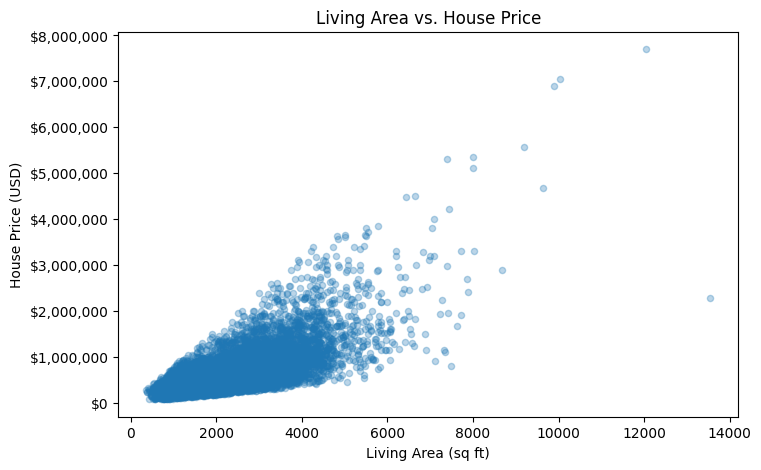

In [197]:
# Visual spread of sqft_living to price

ax = df_housesales.plot(
    kind='scatter',
    x='sqft_living',
    y='price',
    figsize=(8, 5),
    alpha=0.3
)

ax.set_title('Living Area vs. House Price')
ax.set_xlabel('Living Area (sq ft)')
ax.set_ylabel('House Price (USD)')

#change scientific notation to interpretable numbers 
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, pos: f'${x:,.0f}')
)

In [198]:
# Calculate correlation factor
df_housesales['price'].corr(df_housesales['sqft_living'], method='spearman')

np.float64(0.643993167942674)

The Spearman correlation coefficient is 0.64, indicating a moderate positive relationship between living area and house price. This suggests that larger houses generally tend to have higher prices. As a next step, we will check whether this relationship persists once the lot area is included. 

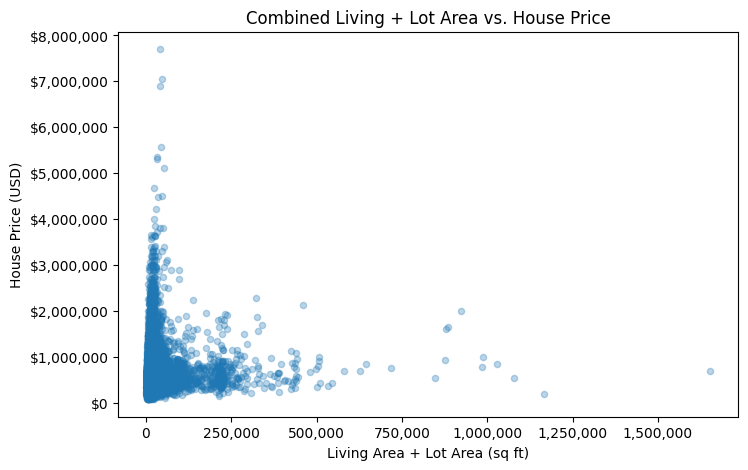

In [199]:
# Visual spread of sqft_living plus sqft_lot to price
df_housesales["sqft_sum"] = df_housesales['sqft_living'] + df_housesales['sqft_lot']
#df_housesales.plot(kind='scatter', x='sqft_sum', y='price')



import matplotlib.ticker as ticker

ax = df_housesales.plot(
    kind='scatter',
    x='sqft_sum',
    y='price',
    figsize=(8, 5),
    alpha=0.3
)

ax.set_title('Combined Living + Lot Area vs. House Price')
ax.set_xlabel('Living Area + Lot Area (sq ft)')
ax.set_ylabel('House Price (USD)')

#change scientific notation to interpretable numbers 
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, pos: f'${x:,.0f}')
)

ax.xaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, pos: f'{x:,.0f}')
)


In [200]:
# Calculate Correlation Factor
df_housesales['price'].corr(df_housesales['sqft_sum'], method='spearman')

np.float64(0.17828851117123484)

The Spearman correlation coefficient of 0.18 indicates a weak positive relationship between total square footage (Living Area + Lot size) and house price. This suggests that larger total property areas are only weakly associated with higher house prices.

#### Final Plots:

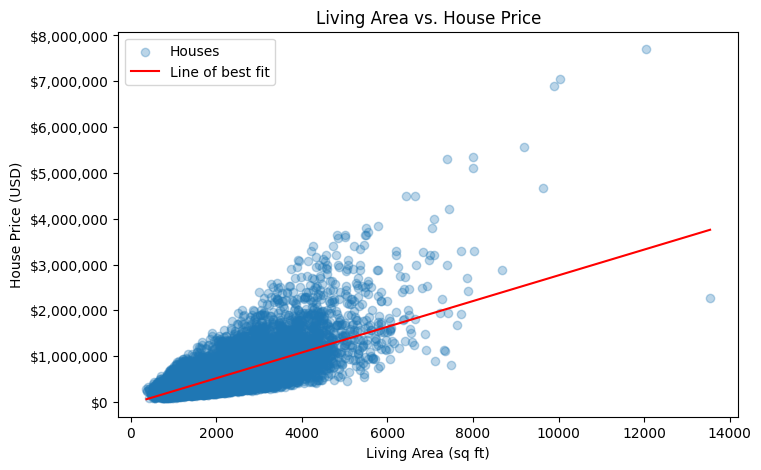

In [201]:
import matplotlib.ticker as ticker

# Scatter plot with correlation line
plt.figure(figsize=(8, 5))

# Create scatter plot
plt.scatter(
    df_housesales['sqft_living'],
    df_housesales['price'],
    alpha=0.3,
    label='Houses'
)

# Calculate slope and intercept for the line of best fit
m, b = np.polyfit(
    df_housesales['sqft_living'],
    df_housesales['price'],
    1
)

# Plot the line of best fit
x_vals = np.linspace(
    df_housesales['sqft_living'].min(),
    df_housesales['sqft_living'].max(),
    100
)

plt.plot(
    x_vals,
    m * x_vals + b,
    color='red',
    label='Line of best fit'
)

# Get current axes
ax = plt.gca()

# Change scientific notation to readable numbers
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, pos: f'${x:,.0f}')
)

# Add title and labels
plt.title('Living Area vs. House Price')
plt.xlabel('Living Area (sq ft)')
plt.ylabel('House Price (USD)')

plt.legend()

plt.savefig(
    "images/price_livingarea.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

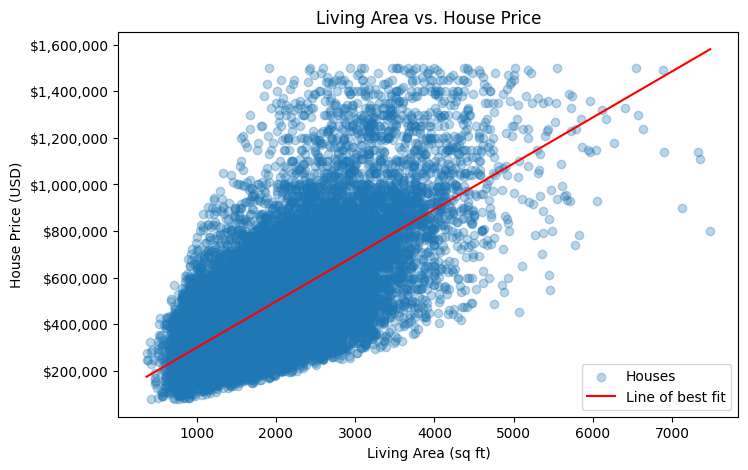

In [202]:
# Create subset for visualization, removing extreme outliers
plot_data = df_housesales[df_housesales['price'] <= 1_500_000]

plt.figure(figsize=(8, 5))

plt.scatter(
    plot_data['sqft_living'],
    plot_data['price'],
    alpha=0.3,
    label='Houses'
)

# Line of best fit
m, b = np.polyfit(
    plot_data['sqft_living'],
    plot_data['price'],
    1
)

x_vals = np.linspace(
    plot_data['sqft_living'].min(),
    plot_data['sqft_living'].max(),
    100
)

plt.plot(
    x_vals,
    m * x_vals + b,
    color='red',
    label='Line of best fit'
)

# Format y-axis
ax = plt.gca()
ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'${x:,.0f}')
)

plt.title('Living Area vs. House Price')
plt.xlabel('Living Area (sq ft)')
plt.ylabel('House Price (USD)')
plt.legend()
plt.show()

#### Conclusions
- Living area and house price show a moderate positive correlation, indicating that smaller houses generally have lower sale prices. **Hypothesis 1 can be confirmed.**
- Total property size (sqft_sum) has only a weak positive correlation with house price, suggesting that overall property size is less useful for explaining price than living area.
- To compare properties independently of their size, price per square foot will be used as a key variable in the following analyses. This helps us identify properties that may be relatively undervalued and therefore attractive to Erin as potential investments.

In [203]:
#Create new variable: Price per sqft
housing_subset['price_sqft'] = round(housing_subset['price'] / housing_subset['sqft_living'],2)


### H2: Relationship Between House Grade, Condition, and Price per Square Foot

#### Hypothesis 2a: Higher-graded houses have a higher price per square foot

##### Descriptives

The first step is to explore the variable grade and to determine a sensible cutoff threshold to find suitable properties for Erin. 

In [204]:
#Descriptives 
print(housing_subset['grade'].describe().round(2))
print(housing_subset['grade'].isnull().sum())

count    21420.00
mean         7.66
std          1.17
min          3.00
25%          7.00
50%          7.00
75%          8.00
max         13.00
Name: grade, dtype: float64
0


Expectedly, there are no missing values. The mean lies at 7.66, the minimum grade at 3 and the maximum grade in the dataset is 13. Now, let's look at the median and the distribution.

In [205]:
#Checking out a sensible threshold 
print(housing_subset['grade'].median())  # Median
print(housing_subset['grade'].value_counts().sort_index())

7.0
grade
3        1
4       27
5      234
6     1995
7     8889
8     6041
9     2606
10    1130
11     396
12      88
13      13
Name: count, dtype: int64


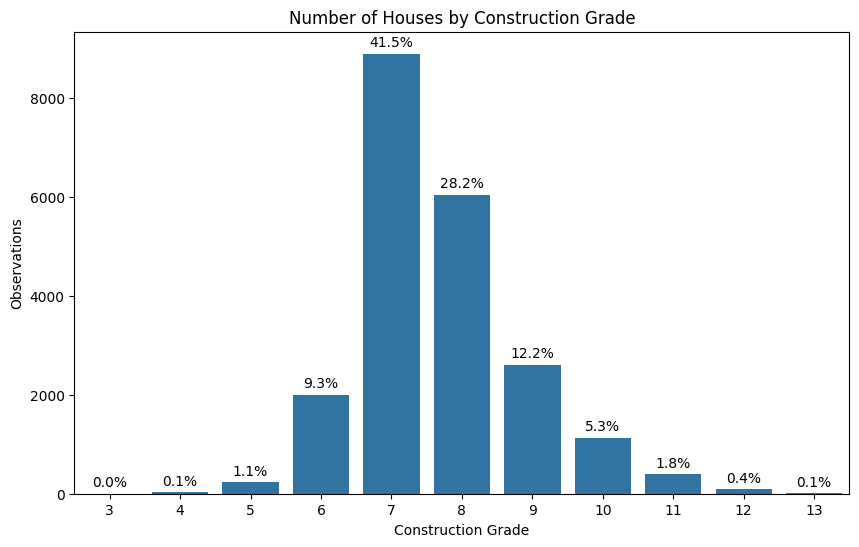

In [206]:
# Count plot: how many offers for each construction grade?
plt.figure(figsize=(10, 6))

ax = sns.countplot(x='grade', data=housing_subset)

plt.title('Number of Houses by Construction Grade')
plt.xlabel('Construction Grade')
plt.ylabel('Observations')

total = len(housing_subset)

for container in ax.containers:
    labels = [f'{value / total * 100:.1f}%' for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3)

plt.show()


The distribution is concentrated around grades 7 and 8, which together account for approximately 70% of all properties. The median construction grade is 7, while the mean is 7.66. Since Erin is looking for affordable investment opportunities rather than the highest-grade properties, we set grade 7 as the minimum threshold. This allows us to focus on properties with average-or-better construction quality while still retaining a broad range of potentially undervalued homes.

##### EDA: Grade and Price per Sqft

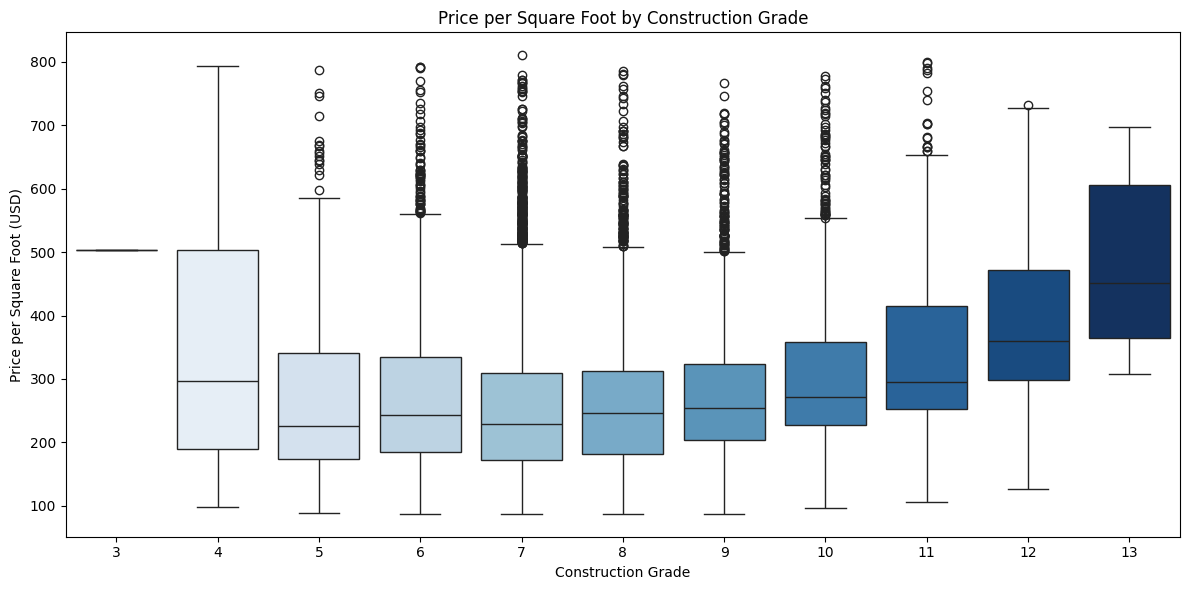

In [207]:
# H2a: Relationship between construction grade and price per square foot
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=housing_subset,
    x='grade',
    y='price_sqft',
    hue='grade',
    palette='Blues',
    legend=False
)

plt.title('Price per Square Foot by Construction Grade')
plt.xlabel('Construction Grade')
plt.ylabel('Price per Square Foot (USD)')

plt.tight_layout()
plt.savefig(
    'images/price_sqft_by_grade.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [208]:
# Summary statistics by construction grade
grade_summary = (
    housing_subset
    .groupby('grade')['price_sqft']
    .agg(['median', 'count'])
    .rename(columns={
        'median': 'Median Price per Sqft',
        'count': 'Number of Houses'
    })
    .round(2)
)

grade_summary

,Median Price per Sqft,Number of Houses
grade,,
3,503.85,1
4,297.26,27
5,225.90,234
6,243.48,1995
7,229.26,8889
8,247.15,6041
9,254.79,2606
10,271.95,1130
11,295.38,396


The median price per square foot does not increase consistently with construction grade. It reaches its lowest level at grade 7 ($228.44/sqft) and generally increases from grade 7 onward. However, grades with very few observations should be interpreted with caution. For example, grade 3 contains only one house, while grades 4 and 13 contain 27 and 13 houses respectively. These small sample sizes make their median prices less reliable. The Spearman correlation will therefore be used to assess the overall direction and strength of the relationship.

In [209]:
spearman_corr = housing_subset['grade'].corr(
    housing_subset['price_sqft'],
    method='spearman'
)

print(f"Spearman correlation between grade and price per sqft: {spearman_corr:.2f}")

Spearman correlation between grade and price per sqft: 0.11


**Conclusion: H2a not supported by the data** 

The Spearman correlation between construction grade and price per square foot is 0.12, indicating a very weak positive relationship. This suggests that higher construction grades are barely associated with higher prices per square foot. Therefore, H2a is not supported by the data.

#### Hypothesis 2b: Houses in better condition have a higher price per square foot

#### Descriptives

H2b: The better the house's condition, the higher the price per sqft. 

Variable "condition": descriptive statistics incl finding a sensible threshold 

Findings: 

- 21597 observations, all integers, no missing values 
- variable runs from condition 1 --> condition 5
- mean 3, median 3 --> normally distributed, 3 is a good threshold for zipcode analysis 

The first step is to explore the variable grade and to determine a sensible cutoff threshold to find suitable properties for Erin. 

In [210]:
#Descriptives 
print(housing_subset['condition'].describe().round(2))
print(housing_subset['condition'].isnull().sum())

count    21420.00
mean         3.41
std          0.65
min          1.00
25%          3.00
50%          3.00
75%          4.00
max          5.00
Name: condition, dtype: float64
0


Again, there are no missing values, which is expected since these were accounted for during data cleaning. The mean lies at 3.41, the minimum condition at 1 and the maximum condition in the dataset is 5. Now, let's look at the median and the distribution.

In [211]:
#Checking out a sensible threshold 
print(housing_subset['condition'].median())  # Median
print(housing_subset['condition'].value_counts().sort_index())

3.0
condition
1       28
2      162
3    13900
4     5643
5     1687
Name: count, dtype: int64


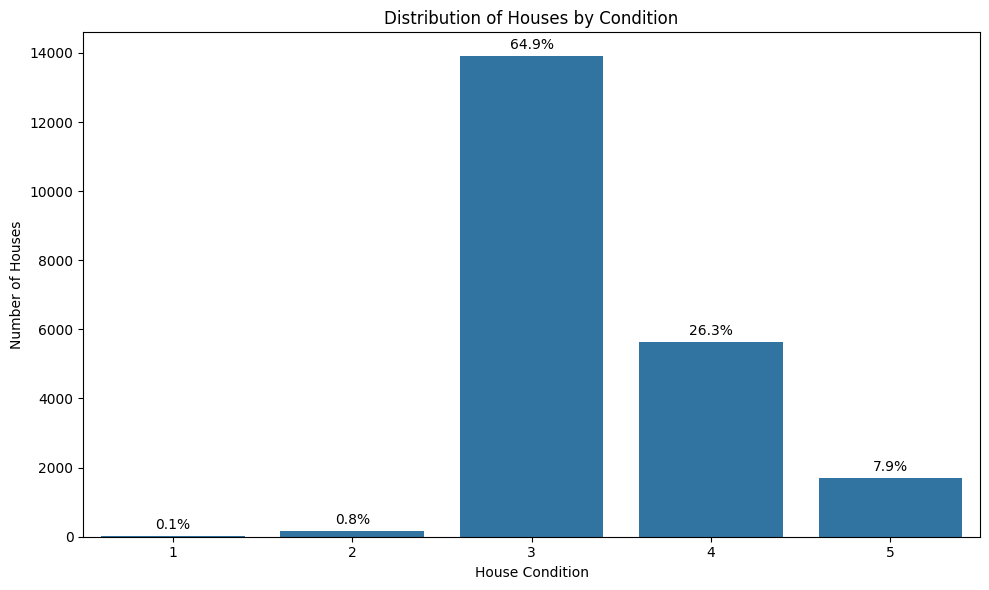

In [212]:
#Count plot: how many houses per condition?
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    x='condition',
    data=housing_subset
)

plt.title('Distribution of Houses by Condition')
plt.xlabel('House Condition')
plt.ylabel('Number of Houses')

# Add percentages
total = len(housing_subset)

for container in ax.containers:
    labels = [
        f'{value / total * 100:.1f}%'
        for value in container.datavalues
    ]
    ax.bar_label(container, labels=labels, padding=3)

plt.tight_layout()
plt.show()

The distribution is strongly concentrated around condition 3, which accounts for approximately 65% of all properties. The median and mean condition are both 3, indicating that condition 3 represents the center of the dataset. Since Erin is looking for affordable investment opportunities with potential for improvement, we set condition 3 as the minimum threshold. This allows us to focus on properties with average-or-better condition while still identifying properties that may offer renovation potential.

#### EDA: Condition & Price per Sqft

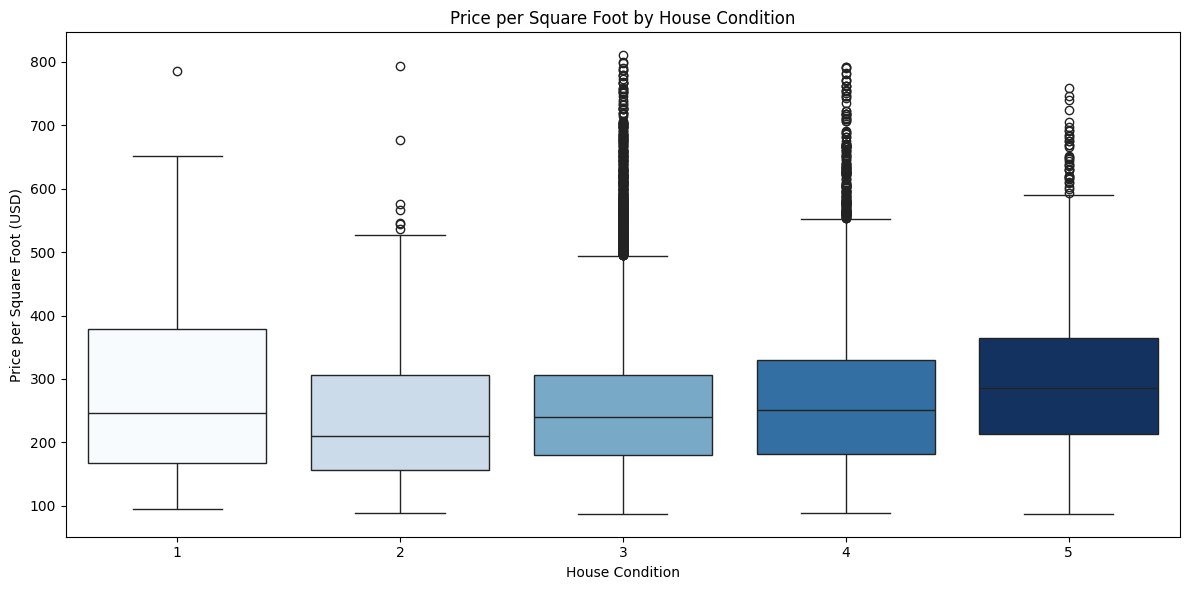

In [213]:
# H2b: Relationship between house condition and price per square foot
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=housing_subset,
    x='condition',
    y='price_sqft',
    hue='condition',
    palette='Blues',
    legend=False
)

plt.title('Price per Square Foot by House Condition')
plt.xlabel('House Condition')
plt.ylabel('Price per Square Foot (USD)')

plt.tight_layout()
plt.savefig(
    'images/price_sqft_by_condition.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [214]:
# Summary statistics by condition
condition_summary = (
    housing_subset
    .groupby('condition')['price_sqft']
    .agg(['median', 'count'])
    .rename(columns={
        'median': 'Median Price per Sqft',
        'count': 'Number of Houses'
    })
    .round(2)
)

condition_summary

,Median Price per Sqft,Number of Houses
condition,,
1,246.80,28
2,210.57,162
3,239.85,13900
4,250.87,5643
5,285.33,1687


In [215]:
spearman_corr = housing_subset['condition'].corr(
    housing_subset['price_sqft'],
    method='spearman'
)

print(f"Spearman correlation between condition and price per sqft: {spearman_corr:.2f}")

Spearman correlation between condition and price per sqft: 0.10


**Conclusion: H2b not supported by the data** 

The Spearman correlation between house condition and price per square foot is 0.10, indicating only a very weak positive relationship. While higher-condition houses tend to have slightly higher prices per square foot, the relationship is too weak to provide meaningful support for the hypothesis.

### Hypothesis 3: Old, unrenovated houses will have a smaller price

#### Descriptives

As a first step, we will look at the distribution of the variables `yr_built`(building age) and `yr_renovated`(renovation status)

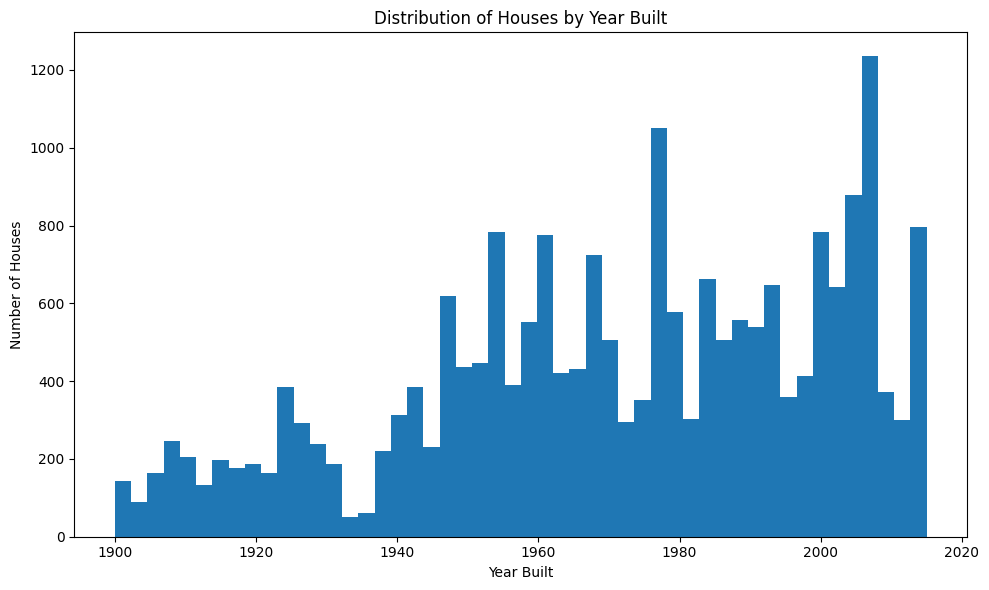

In [216]:
# Distribution of year built
plt.figure(figsize=(10, 6))

housing_subset['yr_built'].plot(
    kind='hist',
    bins=50
)

plt.title('Distribution of Houses by Year Built')
plt.xlabel('Year Built')
plt.ylabel('Number of Houses')

plt.tight_layout()
plt.show()

The dataset contains properties built between approximately 1900 and 2015, with a higher concentration of newer houses. The broad age range provides sufficient variation to investigate whether older properties are associated with lower prices per square foot.

To look at the amount of properties that are unrenovated, we need to create a new, binary variable that tells us whether a house is renovated or not.

In [217]:
#create a new column to categorize renovated houses
def renovated(value):
    if value > 0:
        return "renovated"
    else:
        return "unrenovated"

# Create a new column using map()
housing_subset['renovated'] = housing_subset['yr_renovated'].map(renovated)

Now, the amount of houses in each renovation category can be plotted.

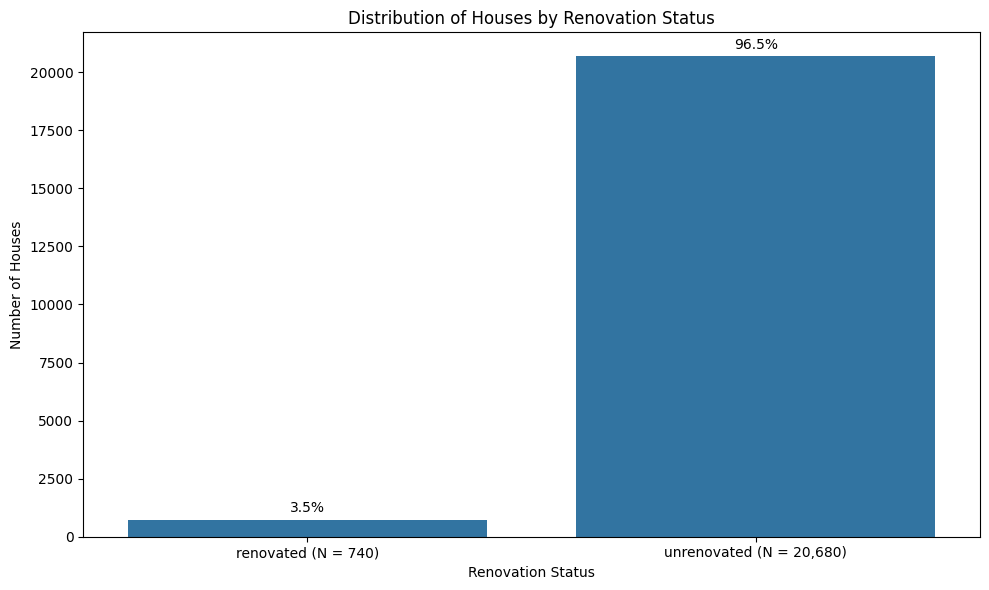

In [218]:
# Count houses in each renovation category
renovation_counts = housing_subset['renovated'].value_counts()

order = ['renovated', 'unrenovated']

labels = [
    f'{status} (N = {renovation_counts[status]:,})'
    for status in order
]

#plot renovated vs. unrenovated houses
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    x='renovated',
    data=housing_subset,
    order=order
)

# Set tick positions and labels
ax.set_xticks(range(len(order)))
ax.set_xticklabels(labels)

plt.title('Distribution of Houses by Renovation Status')
plt.xlabel('Renovation Status')
plt.ylabel('Number of Houses')

# Add percentages
total = len(housing_subset)

for container in ax.containers:
    labels_pct = [
        f'{value / total * 100:.1f}%'
        for value in container.datavalues
    ]
    ax.bar_label(container, labels=labels_pct, padding=3)

plt.tight_layout()
plt.show()

Only 3.4% of the houses in the dataset have been renovated, while 96.6% remain unrenovated. This indicates that renovated properties are relatively rare, leaving a large pool of unrenovated houses that could potentially offer renovation opportunities for Erin.

#### EDA: House age, Renovation status and Price per sqft

The hypothesis H3 was that old and unrenovated houses are cheaper than old renovated properties. As a first step, let's examine the relationship between the price per sqft and the building age. 

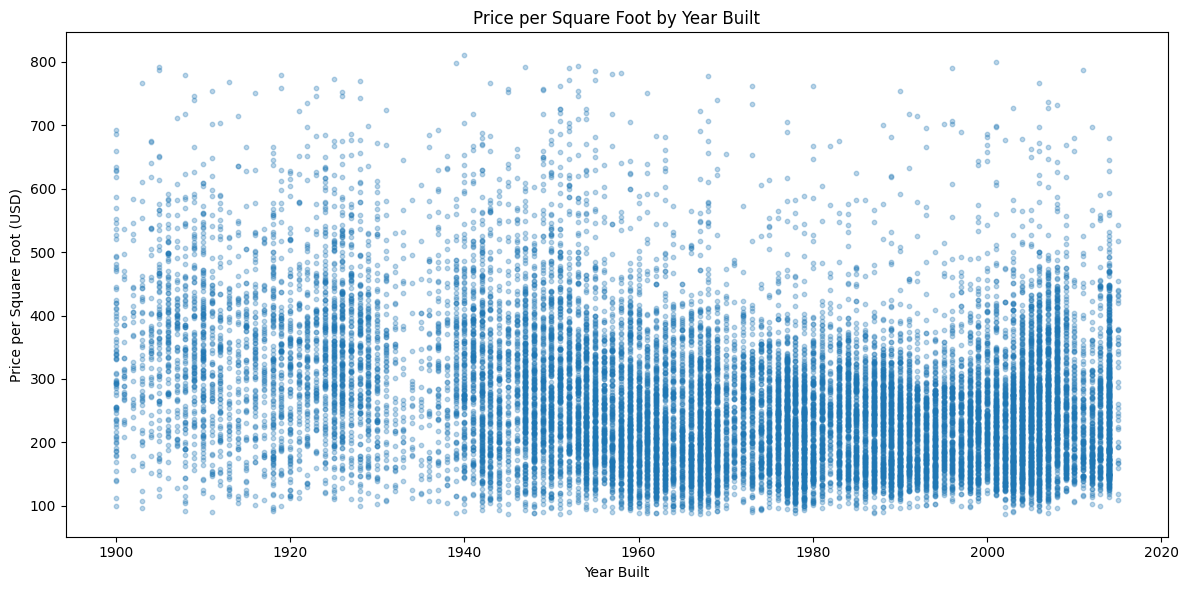

In [219]:
# Relationship between year built and price per square foot
plt.figure(figsize=(12, 6))

plt.scatter(
    housing_subset['yr_built'],
    housing_subset['price_sqft'],
    alpha=0.3,
    s=10
)

plt.title('Price per Square Foot by Year Built')
plt.xlabel('Year Built')
plt.ylabel('Price per Square Foot (USD)')

plt.tight_layout()
plt.show()

In [220]:
#spearman correlation
spearman_corr = housing_subset['yr_built'].corr(
    housing_subset['price_sqft'],
    method='spearman'
)

print(f"Spearman correlation between building year and price per sqft: {spearman_corr:.2f}")

Spearman correlation between building year and price per sqft: -0.25


The scatter plot shows substantial variation in price per square foot across all construction years, with no clear linear pattern. The Spearman correlation of −0.24 indicates a weak negative relationship, suggesting that newer houses tend to have slightly lower prices per square foot. However, the relationship is weak, meaning that year built alone is not a strong predictor of price per square foot.

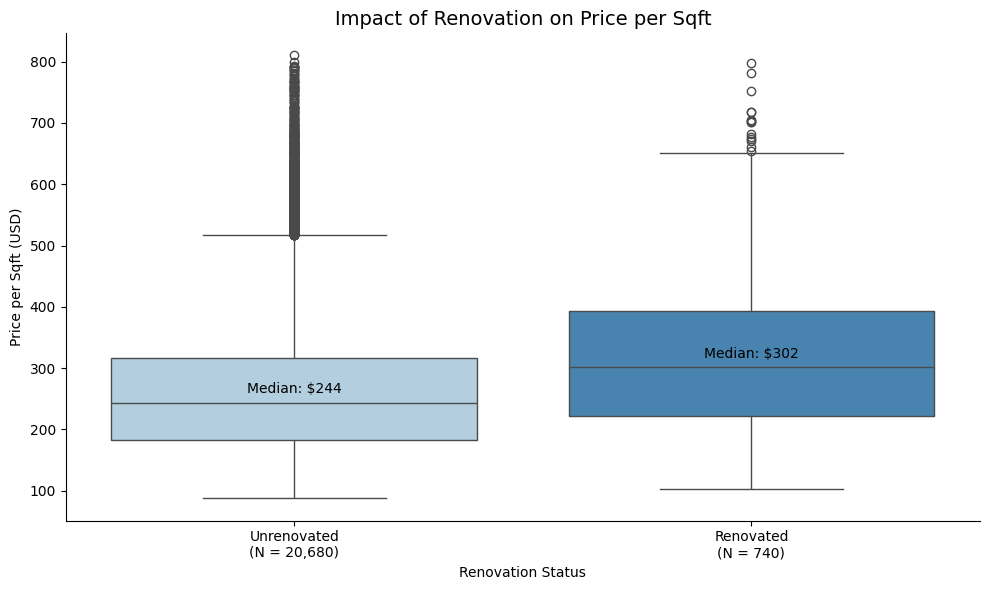

In [221]:
#impact of renovation on house price: Boxplot

plt.figure(figsize=(10, 6))

order = ['unrenovated', 'renovated']

ax = sns.boxplot(
    data=housing_subset,
    x='renovated',
    y='price_sqft',
    hue='renovated',
    order=order,
    palette='Blues',
    legend=False
)

plt.title(
    'Impact of Renovation on Price per Sqft',
    fontsize=14
)
plt.xlabel('Renovation Status')
plt.ylabel('Price per Sqft (USD)')

# Add sample sizes
counts = housing_subset['renovated'].value_counts()

ax.set_xticks(range(len(order)))
ax.set_xticklabels([
    f'Unrenovated\n(N = {counts["unrenovated"]:,})',
    f'Renovated\n(N = {counts["renovated"]:,})'
])

# Add median values
medians = housing_subset.groupby('renovated')['price_sqft'].median()

for i, status in enumerate(order):
    ax.text(
        i,
        medians[status] + 15,
        f'Median: ${medians[status]:.0f}',
        ha='center'
    )

plt.tight_layout()
sns.despine()

plt.savefig(
    'images/price_sqft_renovation.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [222]:
#confirming with Mann-Whitney U test 
from scipy.stats import mannwhitneyu

renovated = housing_subset.loc[
    housing_subset['renovated'] == 'renovated',
    'price_sqft'
]

unrenovated = housing_subset.loc[
    housing_subset['renovated'] == 'unrenovated',
    'price_sqft'
]

u_stat, p_value = mannwhitneyu(
    renovated,
    unrenovated,
    alternative='greater'
)

print(f"Mann-Whitney U statistic: {u_stat:.0f}")
print(f"p-value: {p_value:.4f}")

Mann-Whitney U statistic: 9806608
p-value: 0.0000


There is a difference in price per square foot for renovated vs. unrenovated houses: the median price for renovated houses is $302 while unrenovated houses sell for a median of $243. The one-sided Mann-Whitney U-test confirms that there is evidence for a statistically significant difference in price per sqft between renovated and unrenovated properties (p < 0.001).

After examining the relationship between price and renovation, we can now examine whether this difference is even larger for older houses. Old houses here are defined as the oldest 30% of houses, which, in the case of the dataset, are all houses built between 1900 and 1955. 

In [223]:
# Does renovation play a role for old houses?
#subset old houses (oldest 30%)
mask = housing_subset['yr_built'].quantile(0.3)
df_oldhouses = housing_subset.loc[housing_subset['yr_built'] < mask]

counts = df_oldhouses['renovated'].value_counts()
percentages = df_oldhouses['renovated'].value_counts(normalize=True) * 100

print(pd.DataFrame({
    'Number of Houses': counts,
    'Percentage': percentages.round(1)
}))

print(f'\nNewest house in this dataset: built in',df_oldhouses['yr_built'].max())

             Number of Houses  Percentage
renovated                                
unrenovated              5792        91.2
renovated                 562         8.8

Newest house in this dataset: built in 1955


Among the oldest 30% of houses, roughly 91% are unrenovated and 9% are renovated. Let's look at whether the price per sqft is lower for older unrenovated homes compared to renovated properties.

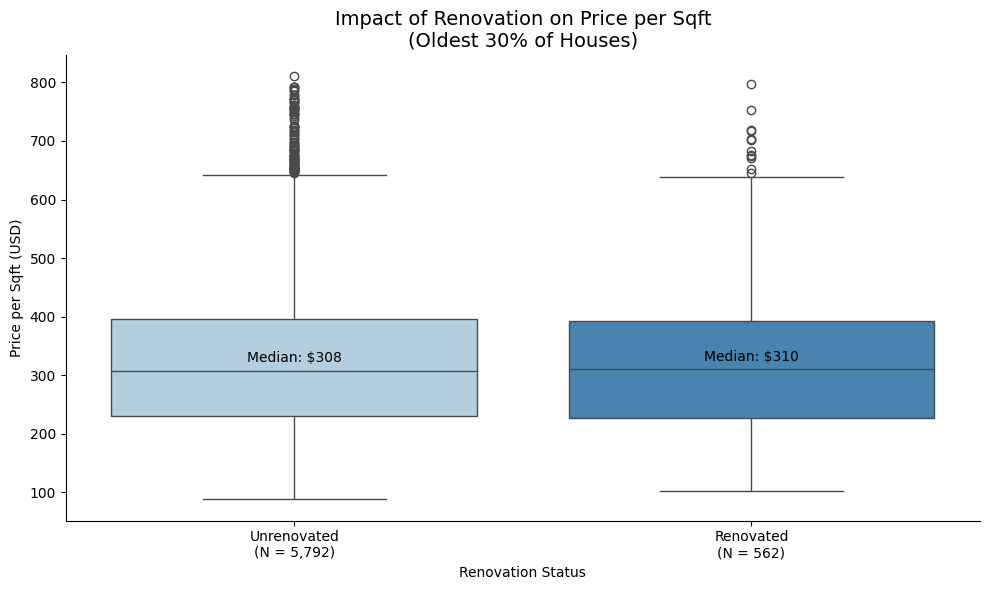

In [224]:
# Boxplot of price per sqft for older renovated vs. unrenovated houses

plt.figure(figsize=(10, 6))

order = ['unrenovated', 'renovated']

ax = sns.boxplot(
    data=df_oldhouses,
    x='renovated',
    y='price_sqft',
    hue='renovated',
    order=order,
    palette='Blues',
    legend=False
)

plt.title(
    'Impact of Renovation on Price per Sqft\n'
    '(Oldest 30% of Houses)',
    fontsize=14
)
plt.xlabel('Renovation Status')
plt.ylabel('Price per Sqft (USD)')

# Add sample sizes
counts = df_oldhouses['renovated'].value_counts()

ax.set_xticks(range(len(order)))
ax.set_xticklabels([
    f'Unrenovated\n(N = {counts["unrenovated"]:,})',
    f'Renovated\n(N = {counts["renovated"]:,})'
])

# Add median values
medians = df_oldhouses.groupby('renovated')['price_sqft'].median()

for i, status in enumerate(order):
    ax.text(
        i,
        medians[status] + 15,
        f'Median: ${medians[status]:.0f}',
        ha='center'
    )

plt.tight_layout()
sns.despine()

plt.savefig(
    'images/price_sqft_renovation.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [225]:
#confirming with Mann-Whitney U test 
from scipy.stats import mannwhitneyu

renovated_old = df_oldhouses.loc[
    df_oldhouses['renovated'] == 'renovated',
    'price_sqft'
]

unrenovated_old = df_oldhouses.loc[
    df_oldhouses['renovated'] == 'unrenovated',
    'price_sqft'
]

u_stat, p_value = mannwhitneyu(
    renovated_old,
    unrenovated_old,
    alternative='greater'
)

print(f"Mann-Whitney U statistic: {u_stat:.0f}")
print(f"p-value: {p_value:.4f}")

Mann-Whitney U statistic: 1637020
p-value: 0.4098


#### Conclusion H3 not supportoed by the data: 
- For the oldest 30% of houses, the median price per square foot is almost identical for renovated and unrenovated properties (around 300$ per sqft). The one-sided Mann-Whitney U-test confirms that there is no evidence for a statistically significant difference in price per sqft between renovated and unrenovated old properties. 

# 6) Recommendations: Suitable zipcodes

To identify potential areas for Erin's property search, we make the assumption that disadvantaged neighborhoods contain a higher concentration of older and unrenovated properties. We use these characteristics as proxies to identify potential geographic clusters. We then apply affordability, condition, and construction-grade criteria to narrow the search to properties that align with Erin's investment strategy.

| Assumption | Criterion | Filter |
|----------|----------|----------|
| Disadvantaged neighborhoods will contain clusters of properties that are **old** and **unrenovated**. | Age | Properties in the **oldest 30%** (`yr_built` ≤ 30th percentile) |
|  | Renovation status | **Unrenovated** |
| Erin is looking for affordable investment opportunities. | Affordability | Price per sqft: **lowest 30%** |
| Profitable investment opportunities should have an **average-or-better condition and construction grade** to limit additional investment costs. | Construction grade | `grade ≥ 7` |
|  | Condition | `condition ≥ 3` |

## Prepare Dataframe

As a first step, renovated houses will be excluded from the analysis. Based on the assumption that disadvantaged neighborhoods contain a higher concentration of older and unrenovated properties, we focus on unrenovated houses to help identify these potential geographic clusters. 

In [226]:
### Filter dataframe: only unrenovated houses 
mask_unrenovated = housing_subset['renovated'] == 'unrenovated'
unren_subset = housing_subset[mask_unrenovated].copy()
unren_subset.head()

,id,price,date,yr_built,yr_renovated,zipcode,lat,long,grade,condition,sqft_living,sqft_lot,price_sqft,renovated
7316,2202500290,435000,2014-05-02,1954,0,98006,47.5746,-122.135,7,4,1450,8800,300.00,unrenovated
20586,7853361370,555000,2014-05-02,2012,0,98065,47.5150,-121.870,8,3,3310,6500,167.67,unrenovated
1040,7197300105,550000,2014-05-02,1976,0,98052,47.6830,-122.114,7,4,1940,10500,283.51,unrenovated
20543,3438501320,295000,2014-05-02,2009,0,98106,47.5489,-122.363,7,3,1630,1368,180.98,unrenovated
9587,472000620,790000,2014-05-02,1951,0,98117,47.6833,-122.400,9,4,2600,4750,303.85,unrenovated


Erin's affordability, condition, and construction-grade criteria are then applied to identify properties that may offer investment opportunities while limiting additional investment costs.

In [227]:
# Set additional criteria for the property search

price_threshold = unren_subset['price_sqft'].quantile(0.30) #affordable, potentially undervalues properties
age_threshold = unren_subset['yr_built'].quantile(0.30) #target older properties 

grade_threshold = 7 #average-or-better construction grade
condition_threshold = 3 #average-or-better condition

In [228]:
age_threshold

np.float64(1958.0)

In [229]:
#Add new column to identify whether houses correspond to the filters 
# Add new column to identify whether houses meet all filter criteria

unren_subset['filters_apply'] = (
    (unren_subset['yr_built'] <= age_threshold) & #neighborhood: 
    (unren_subset['price_sqft'] <= price_threshold) & #affordability: lowest price
    (unren_subset['grade'] >= grade_threshold) & # grade 
    (unren_subset['condition'] >= condition_threshold) #condition
)

unren_subset.head()

,id,price,date,yr_built,yr_renovated,zipcode,lat,long,grade,condition,sqft_living,sqft_lot,price_sqft,renovated,filters_apply
7316,2202500290,435000,2014-05-02,1954,0,98006,47.5746,-122.135,7,4,1450,8800,300.00,unrenovated,False
20586,7853361370,555000,2014-05-02,2012,0,98065,47.5150,-121.870,8,3,3310,6500,167.67,unrenovated,False
1040,7197300105,550000,2014-05-02,1976,0,98052,47.6830,-122.114,7,4,1940,10500,283.51,unrenovated,False
20543,3438501320,295000,2014-05-02,2009,0,98106,47.5489,-122.363,7,3,1630,1368,180.98,unrenovated,False
9587,472000620,790000,2014-05-02,1951,0,98117,47.6833,-122.400,9,4,2600,4750,303.85,unrenovated,False


In [230]:
#filter dataframe for only true values 
results_subset = unren_subset[(unren_subset['filters_apply'] == True)]

#How many Houses for Erin? >filter for nunique because some houses are sold more than once
filtered = results_subset['id'].nunique()
total = housing_subset['id'].nunique()

pct = round(filtered / total * 100, 2)

print(f"Filtered dataset: {filtered} Houses. \nThat is {pct}% of the original dataset containing {total} unique houses")

Filtered dataset: 595 Houses. 
That is 2.78% of the original dataset containing 21420 unique houses


In [231]:
housing_subset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21420 entries, 7316 to 16580
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            21420 non-null  int64         
 1   price         21420 non-null  int64         
 2   date          21420 non-null  datetime64[ns]
 3   yr_built      21420 non-null  int64         
 4   yr_renovated  21420 non-null  int64         
 5   zipcode       21420 non-null  int64         
 6   lat           21420 non-null  float64       
 7   long          21420 non-null  float64       
 8   grade         21420 non-null  int64         
 9   condition     21420 non-null  int64         
 10  sqft_living   21420 non-null  int64         
 11  sqft_lot      21420 non-null  int64         
 12  price_sqft    21420 non-null  float64       
 13  renovated     21420 non-null  object        
dtypes: datetime64[ns](1), float64(3), int64(9), object(1)
memory usage: 2.5+ MB


## Find Target Zip Codes

The goal is to direct Erin toward ZIP codes where she can focus her property search. Therefore, we identify the ZIP codes with the highest percentage of houses meeting all of her investment criteria. This allows Erin to prioritize areas with a greater concentration of suitable properties rather than searching the entire market.

In [232]:
# create grouped dataframe
df = unren_subset.groupby(['zipcode', 'filters_apply']).size().unstack(fill_value=0)

#calculate share of suitable objects
df['share_true'] = df[True] / (df[True] + df[False])

#grouped df for all zipcodes 
alzips_perc = df.sort_values('share_true', ascending=False)

#grouped df for the top 5 zipcodes
top5zips = df.sort_values('share_true', ascending=False).head(5).index.tolist()
alzips_perc

filters_apply,False,True,share_true
zipcode,,,
98148,42,13,0.236364
98178,192,57,0.228916
98168,209,49,0.189922
98188,109,23,0.174242
98166,192,36,0.157895
...,...,...,...
98107,251,0,0.000000
98075,353,0,0.000000
98077,193,0,0.000000


## Plot Target Zip Codes

The goal is to point Erin toward ZIP codes where she can focus her property search. Therefore, we want to identify ZIP codes with the highest percentage of houses that meet all of her investment criteria. This allows Erin to prioritize areas where suitable properties are more concentrated, rather than searching the entire market.

In [233]:
# --------------------------------------------------
# Load GeoJSON
# --------------------------------------------------

gdf = gpd.read_file(
    "data/ZIPCODE_AREA_113_6443937376782627580.geojson"
)

# Standardize ZIP code in geographic data
gdf['zipcode'] = (
    gdf['ZIPCODE']
    .astype(str)
    .str.zfill(5)
)


# --------------------------------------------------
# Prepare ZIP statistics
# --------------------------------------------------

# Convert ZIP codes in housing data to strings
allzips = (
    housing_subset['zipcode']
    .astype(str)
    .str.zfill(5)
    .unique()
)

# Keep only ZIP codes that occur in our housing data
filtered_gdf = gdf[
    gdf['zipcode'].isin(allzips)
].copy()


# --------------------------------------------------
# Prepare share of houses meeting criteria
# --------------------------------------------------

zip_stats = alzips_perc.reset_index()

# Make sure ZIP code is a column
zip_stats['zipcode'] = (
    zip_stats['zipcode']
    .astype(str)
    .str.zfill(5)
)


# --------------------------------------------------
# Merge ZIP statistics with geographic data
# --------------------------------------------------

merged = filtered_gdf.merge(
    zip_stats[['zipcode', 'share_true']],
    on='zipcode',
    how='left'
)


# --------------------------------------------------
# Prepare top 5 ZIP codes
# --------------------------------------------------

top5zips = (
    alzips_perc
    .sort_values('share_true', ascending=False)
    .head(5)
    .index
    .astype(str)
    .str.zfill(5)
    .tolist()
)

print("Top 5 ZIP codes:", top5zips)


# Select top 5 from map data
highlight = merged[
    merged['zipcode'].isin(top5zips)
].copy()


Top 5 ZIP codes: ['98148', '98178', '98168', '98188', '98166']


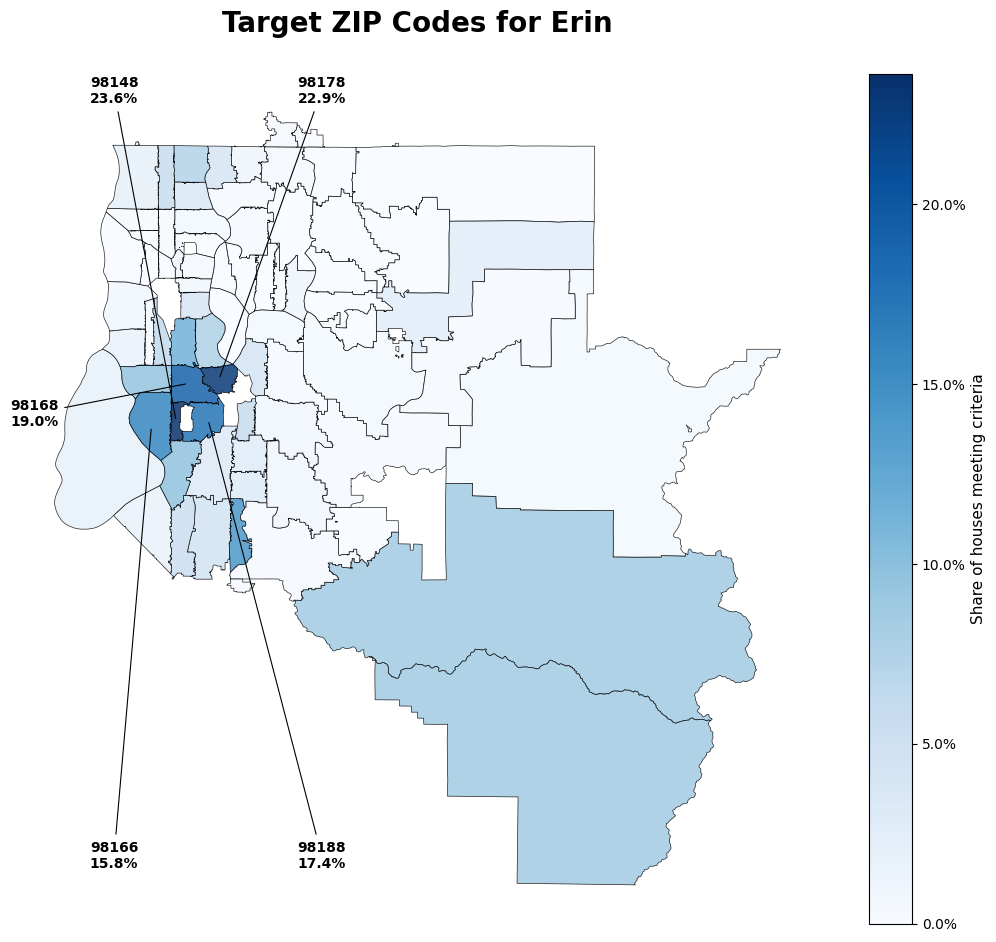

In [234]:
# --------------------------------------------------
# Create map
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 10))


# --------------------------------------------------
# Plot all ZIP codes
# --------------------------------------------------

merged.plot(
    ax=ax,
    column='share_true',
    cmap='Blues',
    legend=True,
    edgecolor='black',
    linewidth=0.5,
    alpha=0.85,
    missing_kwds={'color': 'lightgrey'}
)


# --------------------------------------------------
# Label positions
# --------------------------------------------------

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

label_positions = {
    top5zips[0]: (0.12, 0.98),
    top5zips[1]: (0.38, 0.98),
    top5zips[2]: (0.02, 0.60),
    top5zips[3]: (0.38, 0.08),
    top5zips[4]: (0.12, 0.08)
}


# --------------------------------------------------
# Add labels
# --------------------------------------------------

for _, row in highlight.iterrows():

    zipcode = row['zipcode']

    point = row.geometry.representative_point()

    percentage = row['share_true'] * 100

    if zipcode in label_positions:

        x_rel, y_rel = label_positions[zipcode]

        label_x = xmin + x_rel * (xmax - xmin)
        label_y = ymin + y_rel * (ymax - ymin)

        ax.annotate(
            f"{zipcode}\n{percentage:.1f}%",
            xy=(point.x, point.y),
            xytext=(label_x, label_y),
            ha='center',
            va='center',
            fontsize=10,
            fontweight='bold',
            arrowprops=dict(
                arrowstyle='-',
                color='black',
                linewidth=0.8
            ),
            bbox=dict(
                boxstyle='round,pad=0.25',
                facecolor='white',
                edgecolor='none',
                alpha=0.9
            ),
            zorder=10
        )


# --------------------------------------------------
# Format colorbar
# --------------------------------------------------

import matplotlib.ticker as mtick

cbar = ax.get_figure().axes[-1]

cbar.yaxis.set_major_formatter(
    mtick.PercentFormatter(1.0)
)

cbar.set_ylabel(
    'Share of houses meeting criteria',
    fontsize=11
)


# --------------------------------------------------
# Title
# --------------------------------------------------

ax.set_title(
    "Target ZIP Codes for Erin",
    fontsize=20,
    fontweight='bold',
    pad=30
)

ax.axis('off')


# --------------------------------------------------
# Layout
# --------------------------------------------------

plt.subplots_adjust(
    top=0.90,
    bottom=0.05,
    left=0.02,
    right=0.90
)


# --------------------------------------------------
# Save
# --------------------------------------------------

plt.savefig(
    "images/target_zip_codes.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

The map highlights the five ZIP codes with the highest share of properties meeting Erin’s investment criteria. The highest shares are found in ZIP codes 98148 (23.6%) and 98178 (22.9%), followed by 98168 (19.0%), 98188 (17.4%), and 98166 (15.8%). These areas therefore contain the highest concentration of properties that meet the defined investment criteria.